In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [6]:
iso_data_dir = "../../../data/"
signal_type = "dynamic"  # dynamic or traditional
file_name = "012025_" + signal_type + ".csv"
file_path = iso_data_dir + file_name
date = "1/17/2025"

df = pd.read_csv(file_path)

print(df.head())


  Unnamed: 0  1/1/2025  1/2/2025  1/3/2025  1/4/2025  1/5/2025  1/6/2025  \
0    0:00:00 -0.999300  0.672976 -0.974665  0.038908 -0.059377 -0.028358   
1    0:00:02 -0.999241  0.652066 -0.965220  0.031900 -0.029303  0.036790   
2    0:00:04 -0.999973  0.635609 -0.947643  0.026199  0.001650  0.072859   
3    0:00:06 -0.999976  0.623370 -0.999633  0.013269  0.038735  0.148291   
4    0:00:08 -0.999980  0.613617 -0.999117 -0.003862  0.078129  0.222244   

   1/7/2025  1/8/2025  1/9/2025  ...  1/22/2025  1/23/2025  1/24/2025  \
0  0.649107 -0.609764  1.000063  ...   0.531411  -0.126601  -0.195508   
1  0.661217 -0.607512  0.999998  ...   0.502289  -0.137669  -0.192615   
2  0.665801 -0.598475  0.999995  ...   0.484451  -0.139485  -0.188004   
3  0.670476 -0.594001  0.999991  ...   0.441762  -0.158652  -0.179855   
4  0.672644 -0.588965  0.999988  ...   0.411880  -0.177566  -0.170049   

   1/25/2025  1/26/2025  1/27/2025  1/28/2025  1/29/2025  1/30/2025  1/31/2025  
0   0.123271  -0.767179

In [7]:

# # Iterate over each column (skipping the first unnamed column)
# for column in df.columns[1:]:
#     # Extract the column data
#     data = df[column]
#     column_name = column.replace("/", "-")
#     # Save to a CSV file with the column name as the filename (no header or index)
#     output_file = iso_data_dir + f"{column_name}_dynamic.csv"
#     data.to_csv(output_file, index=False, header=False)
#
# print("Files saved successfully!")

In [7]:
p_bar = 0 # MW
r = 1   # MW

ptarget = p_bar + df[date] * r

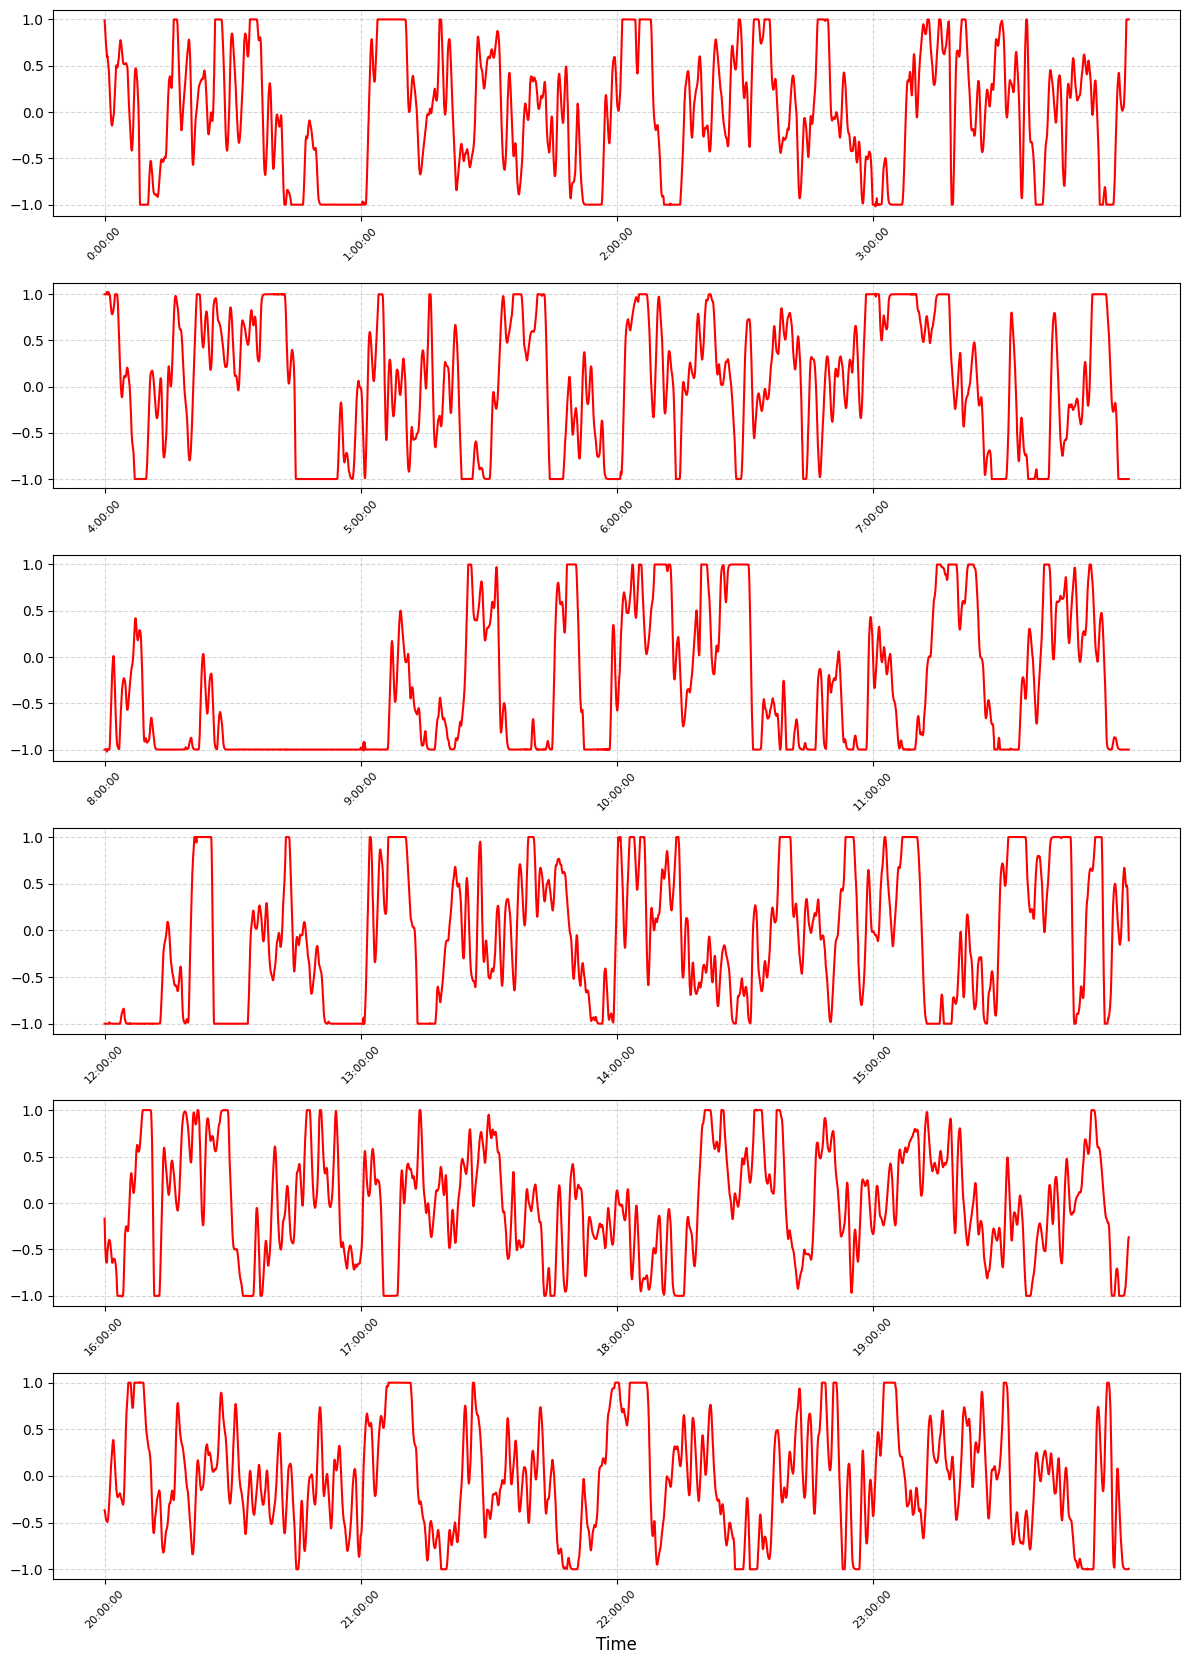

In [8]:
# Extract time labels (assuming the 0th column contains time)
time_labels = df.iloc[:, 0]  # Extract the 0th column for x-axis labels

# Ensure all time_labels are strings
time_labels = [str(label) for label in time_labels]

# Compute ptarget
ptarget = p_bar + df[date] * r

# Number of data points per hour
data_points_per_hour = 1800

# Number of data points per 4-hour interval
data_points_per_4_hours = data_points_per_hour * 4

# Create subplots
fig, axes = plt.subplots(6, 1, figsize=(12, 18))  # 6 rows, 1 column of subplots

# Create the 6 subplots for 4-hour intervals
for i in range(6):
    # Extract data for the current 4-hour interval
    start_idx = i * data_points_per_4_hours
    end_idx = start_idx + data_points_per_4_hours
    interval_time_labels = time_labels[start_idx:end_idx]
    interval_ptarget = ptarget[start_idx:end_idx]

    # Calculate ticks for each hour within the interval
    tick_positions = range(0, len(interval_time_labels), data_points_per_hour)
    tick_labels = [interval_time_labels[j] for j in tick_positions]

    # Plot data in the current subplot
    axes[i].plot(interval_time_labels, interval_ptarget, label=f'Interval {i + 1}', color='red', linestyle='-', markevery=data_points_per_hour)
    axes[i].set_xticks(tick_positions)  # Set x-axis ticks
    axes[i].set_xticklabels(tick_labels, rotation=45, fontsize=8)  # Set tick labels
    # axes[i].set_ylabel('P Target (MW)', fontsize=10)  # Label for y-axis
    axes[i].grid(visible=True, linestyle='--', alpha=0.5)  # Add grid
    # axes[i].legend(fontsize=10)  # Add legend

# Add a shared title and x-label
# fig.suptitle('P Target Over 24 Hours (Split into 4-Hour Intervals)', fontsize=14)
plt.xlabel('Time', fontsize=12)

# Optimize layout and display the plot
plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.show()


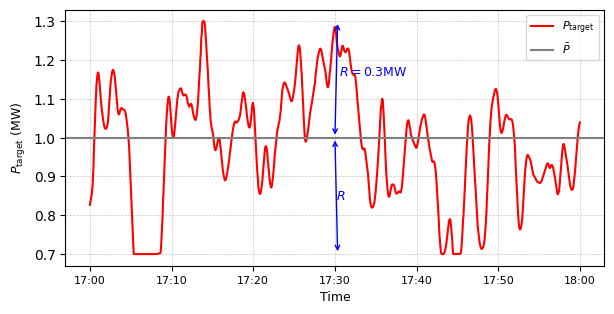

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

# Read the dataset

# Constants
p_bar = 1  # MW
r = 0.3  # MW

# Extract time labels (assuming the 0th column contains time)
time_labels = df.iloc[:, 0]  # Extract the 0th column for x-axis labels as strings
time_labels = [str(label) for label in time_labels]  # Ensure all are strings

# Compute the values for ptarget
ptarget = p_bar + df[date] * r

# Parameters for filtering (customize these)
start_hour = 17
end_hour = 18

# Each hour has 1800 data points (2-second intervals)
data_points_per_hour = 1800
start_idx = start_hour * data_points_per_hour  # Start index for the given range
end_idx = end_hour * data_points_per_hour + 1  # End index for the given range

# Filter data and labels based on the indices
filtered_time_labels = time_labels[start_idx:end_idx]
filtered_ptarget = ptarget[start_idx:end_idx]

# Calculate tick positions for 6 evenly spaced x-ticks
tick_step = len(filtered_time_labels) // 6  # Step size for evenly spaced ticks
tick_positions = list(range(0, len(filtered_time_labels), tick_step))[:6]  # Ensure 6 positions
tick_labels = [filtered_time_labels[i] for i in tick_positions]  # Corresponding tick labels
tick_labels = [':'.join(label.split(':')[:2]) for label in tick_labels]
tick_positions.append(len(filtered_time_labels) - 1)  # Add the last index of the filtered labels
tick_labels.append(':'.join(filtered_time_labels[-1].split(':')[:2]))  # Format and add the last label (removing seconds)


plt.figure(figsize=(6, 3))  # Compact figure size for papers
plt.plot(filtered_time_labels, filtered_ptarget, label=r'$P_\text{target}$',
         color='red', linestyle='-', linewidth=1.5, markevery=tick_step, markersize=3)

# Visual elements
plt.axhline(y=p_bar, color='gray', linestyle='-', linewidth=1.5, label=r'$\bar{P}$')  # Add horizontal line for p_bar

# Add vertical arrows for R (above and below p_bar)
plt.annotate('', xy=(tick_positions[3]+10, p_bar + r), xytext=(tick_positions[3], p_bar),
             arrowprops=dict(arrowstyle='<->', color='blue', lw=1), fontsize=8)
plt.annotate('', xy=(tick_positions[3]+10, p_bar - r), xytext=(tick_positions[3], p_bar),
             arrowprops=dict(arrowstyle='<->', color='blue', lw=1), fontsize=8)

# Add labels for R
plt.text(tick_positions[3]+15, p_bar + r / 2 + 0.02, r'$R=0.3 \text{MW}$', color='blue', fontsize=9, ha='left', va='center')
plt.text(tick_positions[3]+20, p_bar - r / 2, r'$R$', color='blue', fontsize=9, ha='center', va='center')

# X-axis labels and ticks
plt.xticks(tick_positions, tick_labels, fontsize=8)
plt.xlabel('Time', fontsize=9)
plt.ylabel(r'$P_\text{target} \text{ (MW)}$', fontsize=9)

# Grid and legend
plt.grid(visible=True, linestyle='--', linewidth=0.5, alpha=0.7)
plt.legend(fontsize=8)

# Export as PDF (Sigmetrics-style margin adjustments)
plt.tight_layout(pad=0.2)
plt.savefig("plots/rsr_signal" + file_name.split('.')[0]+ ".png", format="png", dpi=300, bbox_inches="tight")
plt.show()


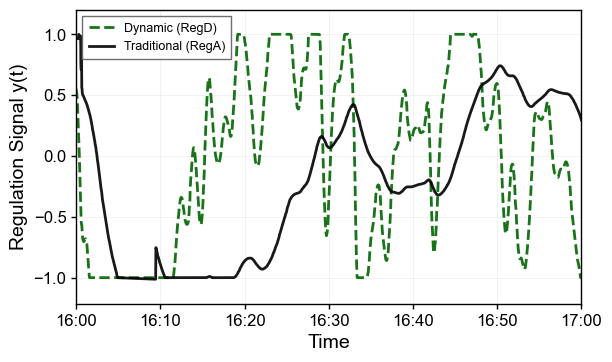

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Set ACM paper style parameters
plt.rcParams.update({
    'font.size': 14,
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica'],
    'axes.labelsize': 14,
    'axes.titlesize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 9,
    'figure.titlesize': 11,
    'lines.linewidth': 1.5,
    'grid.linewidth': 0.6,
    'axes.linewidth': 1.0,
    'xtick.major.width': 1.0,
    'ytick.major.width': 1.0,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'savefig.facecolor': 'white',
    'savefig.edgecolor': 'none'
})

# Constants and inputs
iso_data_dir = "../../../data/"
start_hour = 16  # Start hour (customizable)
end_hour = 17    # End hour (customizable)
data_points_per_hour = 1800  # Assumption: 1800 data points (2-second intervals) per hour
start_idx = start_hour * data_points_per_hour  # Start index for given time range
end_idx = end_hour * data_points_per_hour  # End index for given time range

# Load dynamic and traditional signal datasets
dyn = pd.read_csv(iso_data_dir + "1-8-2025_dynamic.csv", header=None)[0]
trd = pd.read_csv(iso_data_dir + "1-8-2025_traditional.csv", header=None)[0]

# Filter data for the specified time range
dyn_filtered = dyn[start_idx:end_idx]
trd_filtered = trd[start_idx:end_idx]

# Create numerical x-axis
x_axis = range(len(dyn_filtered))

# Generate time labels for display
time_labels = [f"{start_hour + i//data_points_per_hour:02d}:{(i % data_points_per_hour) // 30:02d}"
               for i in range(len(dyn_filtered))]

# ACM single-column width figure (slightly wider than IEEE)
fig, ax = plt.subplots(figsize=(6.0, 3.5), facecolor='white')
ax.set_facecolor('white')

# ACM-style colors (energy-themed, colorblind-friendly)
dynamic_color = 'darkgreen'    # Professional blue
traditional_color = 'black'  # Contrasting magenta
grid_color = '#CCCCCC'       # Light gray

# Plot with ACM-appropriate colors and styles
ax.plot(x_axis, dyn_filtered, label='Dynamic (RegD)', color=dynamic_color,
        linestyle='--', linewidth=2.0, alpha=0.9)
ax.plot(x_axis, trd_filtered, label='Traditional (RegA)', color=traditional_color,
        linestyle='-', linewidth=2.0, alpha=0.9)

num_ticks = 7  # 16:00, 16:10, 16:20, 16:30, 16:40, 16:50, 17:00
tick_positions = []
tick_labels = []

for i in range(num_ticks):
    minutes = i * 10
    hour = start_hour
    minute = minutes

    # Handle hour rollover
    if minute >= 60:
        hour = start_hour + 1
        minute = minute - 60

    # Calculate position in the data
    if hour == start_hour:
        pos = int((minute / 60) * len(time_labels))
    else:
        pos = len(time_labels) - 1  # End of data

    tick_positions.append(pos)
    tick_labels.append(f"{hour}:{minute:02d}")

ax.set_xticks(tick_positions)
ax.set_xticklabels(tick_labels, rotation=0)
ax.set_xlabel('Time', fontweight='normal')
ax.set_ylabel('Regulation Signal y(t)')

# Professional grid
ax.grid(True, linestyle='-', alpha=0.3, linewidth=0.6, color=grid_color)
ax.set_axisbelow(True)

# Move legend to upper left to avoid blocking data
ax.legend(loc='upper left', frameon=True, fancybox=False, shadow=False,
          framealpha=0.95, edgecolor='#666666', facecolor='white',
          borderpad=0.5, columnspacing=1.0)

# Frame from all sides
ax.spines['top'].set_visible(True)
ax.spines['right'].set_visible(True)
ax.spines['bottom'].set_visible(True)
ax.spines['left'].set_visible(True)
ax.spines['top'].set_color('black')
ax.spines['right'].set_color('black')
ax.spines['bottom'].set_color('black')
ax.spines['left'].set_color('black')

# Set axis limits for better visualization
ax.set_xlim(0, len(x_axis)-1)
y_min, y_max = min(min(dyn_filtered), min(trd_filtered)), max(max(dyn_filtered), max(trd_filtered))
y_margin = (y_max - y_min) * 0.1
ax.set_ylim(y_min - y_margin, y_max + y_margin)

# Professional layout
plt.tight_layout(pad=0.2)

# Save in ACM-preferred formats
# plt.savefig("acm_energy_signal_comparison.pdf", format="pdf", dpi=300, bbox_inches="tight",
#             pad_inches=0.02, facecolor='white', edgecolor='none')
plt.savefig("plots/iso_signal_comparison.png", format="png", dpi=300, bbox_inches="tight",
            pad_inches=0.02, facecolor='white', edgecolor='none')

plt.show()

In [11]:
time_labels[-1]

'16:59'

In [12]:
len(dyn_filtered)

1800